# 03 — Thực nghiệm mô hình dự báo churn (Mức 1)

**Đề tài 18 — Mức 1 (Thực tập ngành).** Notebook này đọc kết quả do `ml/src/train.py` sinh ra và vẽ hình, bảng cho Chương 4 (mục 4.4 đến 4.6).

**Cần chạy `python ml\src\train.py` trước.** Notebook này **không huấn luyện lại**, chỉ đọc kết quả đã lưu.

**Protocol (hướng dẫn của cô, Mục 6.1 và 7)**
- Chia 80/20 có stratify, seed 42. Tập test chỉ dùng ở bước đánh giá cuối.
- Trên 80% train: StratifiedKFold 5 fold. Điền thiếu, chuẩn hóa, one-hot nằm trong Pipeline (không rò rỉ).
- 4 mô hình: Dummy, Logistic Regression, Random Forest, Gradient Boosting. Ba mô hình thật được tinh chỉnh bằng lưới nhỏ trong CV, chấm bằng PR-AUC, chỉ trên train.
- Chọn mô hình và hai ngưỡng bằng điểm **out-of-fold** của train. Không chọn gì dựa trên test.
- Không dùng `customerID`, nhãn, hay dữ liệu mô phỏng làm đặc trưng (D-04).

**Cách đọc:** điểm của mô hình là *xác suất theo mô hình trên dữ liệu mẫu IBM Telco*, dùng để **hỗ trợ ưu tiên chăm sóc**, không phải quan hệ nhân quả và không dùng để tự động ra quyết định bất lợi cho khách hàng (R-02, R-07, R-12).

In [1]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.calibration import calibration_curve
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve, brier_score_loss


def find_project_root(start_folder):
    """Đi ngược từ thư mục hiện tại để tìm thư mục gốc dự án (có ml/data/raw)."""
    for folder in [start_folder] + list(start_folder.parents):
        if (folder / "ml" / "data" / "raw").exists():
            return folder
    raise FileNotFoundError("Không tìm thấy thư mục gốc dự án (thiếu ml/data/raw).")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
sys.path.insert(0, str(PROJECT_ROOT / "ml" / "src"))
import evaluate
import preprocessing

RAW_FILE = PROJECT_ROOT / "ml" / "data" / "raw" / "Telco-Customer-Churn.csv"
MODELS_FOLDER = PROJECT_ROOT / "ml" / "models"
PREDICTIONS_FOLDER = PROJECT_ROOT / "ml" / "results" / "predictions"
FIGURE_FOLDER = PROJECT_ROOT / "ml" / "results" / "figures"
METRICS_FOLDER = PROJECT_ROOT / "ml" / "results" / "metrics"
FIGURE_FOLDER.mkdir(parents=True, exist_ok=True)
METRICS_FOLDER.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"

MODEL_KEYS = ["Dummy", "LogisticRegression", "RandomForest", "GradientBoosting"]
DISPLAY_NAMES = {"Dummy": "Dummy", "LogisticRegression": "Logistic Regression",
                 "RandomForest": "Random Forest", "GradientBoosting": "Gradient Boosting"}
MODEL_COLORS = dict(zip(MODEL_KEYS, ["#9E9E9E", "#4C78A8", "#54A24B", "#E45756"]))
COLOR_STAY = "#4C78A8"
COLOR_CHURN = "#E45756"


def format_percent(value):
    return format(value, ".1f").replace(".", ",") + "%"


def format_count(value):
    return format(int(value), ",").replace(",", ".")


def save_figure(figure, file_name):
    figure.tight_layout()
    figure.savefig(FIGURE_FOLDER / file_name, dpi=200, bbox_inches="tight")
    print("Đã lưu hình :", FIGURE_FOLDER / file_name)


def save_table(table, file_name):
    table.to_csv(METRICS_FOLDER / file_name, index=False, encoding="utf-8-sig")
    print("Đã lưu bảng :", METRICS_FOLDER / file_name)


# Đọc kết quả do train.py sinh ra
metadata_path = MODELS_FOLDER / "churn_model_meta_v1.json"
if not metadata_path.exists():
    raise FileNotFoundError("Chưa có " + str(metadata_path) + ". Chạy python ml\\src\\train.py trước.")
with open(metadata_path, "r", encoding="utf-8") as file:
    meta = json.load(file)

oof = pd.read_csv(PREDICTIONS_FOLDER / "oof_train.csv")
test = pd.read_csv(PREDICTIONS_FOLDER / "test_scores.csv")
cv_table = pd.read_csv(METRICS_FOLDER / "model_02_so_sanh_cv.csv")
test_table = pd.read_csv(METRICS_FOLDER / "model_03_so_sanh_test.csv")
threshold_table = pd.read_csv(METRICS_FOLDER / "model_04_nguong.csv")
confusion_table = pd.read_csv(METRICS_FOLDER / "model_05_confusion_matrix.csv")

# Đặc trưng gốc của khách trong tập test (để phân tích lỗi và metric theo nhóm)
features, target, customer_ids = preprocessing.load_raw_data(RAW_FILE)
test_features = features.loc[test["row_index"]].reset_index(drop=True)
y_test = test["y_true"].to_numpy()
y_train = oof["y_true"].to_numpy()

print("Python     :", sys.version.split()[0], "| scikit-learn:", sklearn.__version__, "| pandas:", pd.__version__)
print("Mô hình lưu:", meta["model_name"], "| phiên bản", meta["version"], "| huấn luyện lúc", meta["train_date"])
print("Thư viện lúc huấn luyện:", meta["library_versions"])

Python     : 3.12.3 | scikit-learn: 1.8.0 | pandas: 3.0.2
Mô hình lưu: Gradient Boosting | phiên bản v1 | huấn luyện lúc 2026-10-18T09:59:24
Thư viện lúc huấn luyện: python=3.12.3;scikit-learn=1.8.0;pandas=3.0.2;numpy=2.4.4;joblib=1.5.3


## 1. Tóm tắt protocol và mô hình được chọn

In [2]:
protocol = meta["protocol"]
dataset = meta["dataset"]
summary_rows = [
    ("Dữ liệu", str(dataset["rows"]) + " khách (IBM Telco, dữ liệu mẫu)"),
    ("Mã băm SHA-256 của CSV", dataset["sha256"]),
    ("Chia train/test", str(dataset["train_rows"]) + " / " + str(dataset["test_rows"]) + " (80/20, stratify, seed " + str(meta["seed"]) + ")"),
    ("Cross-validation", "StratifiedKFold " + str(protocol["cv_folds"]) + " fold, xáo trộn, seed " + str(meta["seed"]) + ", chỉ trên train"),
    ("Tiêu chí chọn mô hình", "PR-AUC trung bình 5 fold (average_precision)"),
    ("Số đặc trưng", str(len(meta["feature_columns"])) + " (không có customerID, không có nhãn, không có dữ liệu mô phỏng)"),
    ("Mô hình được chọn", meta["model_name"]),
    ("Tham số tốt nhất", json.dumps(meta["best_params"], ensure_ascii=False)),
    ("Đã hiệu chuẩn (calibration)", "Có (sigmoid)" if meta["calibrated"] else "Không (Brier của bản gốc đã đủ tốt)"),
    ("Ngưỡng Medium (ModelVersions.Threshold)", format(meta["threshold_medium"], ".4f") + "  — Recall >= " + str(protocol["min_recall_medium"]) + " trên điểm out-of-fold"),
    ("Ngưỡng High", ("không có" if meta["threshold_high"] is None else format(meta["threshold_high"], ".4f"))
                    + "  — Precision >= " + str(protocol["min_precision_high"]) + " trên điểm out-of-fold"),
]
protocol_table = pd.DataFrame(summary_rows, columns=["Hạng mục", "Giá trị"])
save_table(protocol_table, "model_00_tom_tat_protocol.csv")
print(meta["selection_note"])
protocol_table

Đã lưu bảng : /home/claude/proj/ml/results/metrics/model_00_tom_tat_protocol.csv
PR-AUC CV của Gradient Boosting hơn Random Forest 0.0059, nhỏ hơn một độ lệch chuẩn giữa các fold (0.0246): chưa đủ cơ sở nói mô hình này hơn đáng kể.


,Hạng mục,Giá trị
0,Dữ liệu,"7043 khách (IBM Telco, dữ liệu mẫu)"
1,Mã băm SHA-256 của CSV,16320c9c1ec72448db59aa0a26a0b95401046bef5d02fd...
2,Chia train/test,"5634 / 1409 (80/20, stratify, seed 42)"
3,Cross-validation,"StratifiedKFold 5 fold, xáo trộn, seed 42, chỉ..."
4,Tiêu chí chọn mô hình,PR-AUC trung bình 5 fold (average_precision)
5,Số đặc trưng,"19 (không có customerID, không có nhãn, không ..."
6,Mô hình được chọn,Gradient Boosting
7,Tham số tốt nhất,"{""learning_rate"": 0.05, ""max_depth"": 2, ""n_est..."
8,Đã hiệu chuẩn (calibration),Không (Brier của bản gốc đã đủ tốt)
9,Ngưỡng Medium (ModelVersions.Threshold),0.3148 — Recall >= 0.75 trên điểm out-of-fold


## 2. So sánh mô hình bằng cross-validation (chỉ trên tập train)

PR-AUC trung bình 5 fold là tiêu chí chọn mô hình. **Thanh sai số** là độ lệch chuẩn giữa các fold: nếu hai mô hình chênh nhau ít hơn thanh sai số thì chưa đủ cơ sở nói mô hình nào hơn.

In [3]:
cv_table

,Mô hình,Tham số tốt nhất,PR-AUC CV (trung bình 5 fold),Độ lệch chuẩn giữa các fold,ROC-AUC (out-of-fold),"F1 tại ngưỡng 0,5 (out-of-fold)",Brier (out-of-fold),"Ngưỡng Recall >= 0,75"
0,Dummy,{},0.2654,0.0001,0.4999,0.0000,0.1949,NaN
1,Logistic Regression,"{""C"": 1, ""class_weight"": null}",0.6614,0.0218,0.8456,0.5929,0.1351,0.3187
2,Random Forest,"{""class_weight"": null, ""max_depth"": 10, ""min_s...",0.6644,0.0221,0.8473,0.5743,0.1345,0.3170
3,Gradient Boosting,"{""learning_rate"": 0.05, ""max_depth"": 2, ""n_est...",0.6702,0.0246,0.8493,0.5859,0.1335,0.3148


Đã lưu hình : /home/claude/proj/ml/results/figures/model_01_pr_auc_cv.png


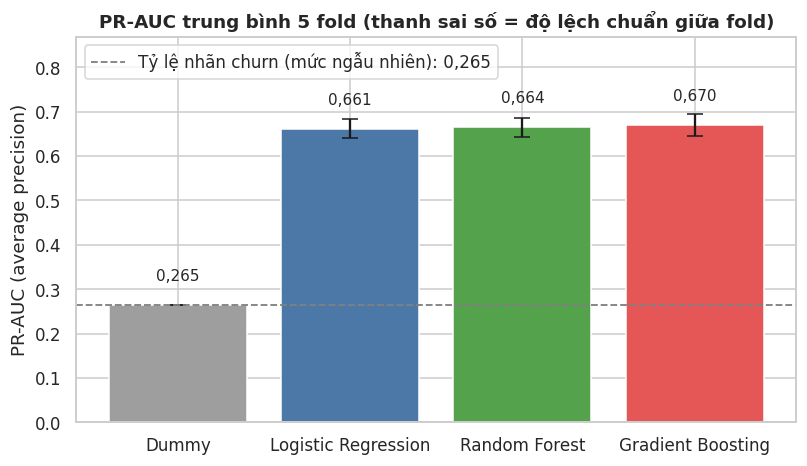

In [4]:
figure, axis = plt.subplots(figsize=(7.5, 4.4))
names = list(cv_table["Mô hình"])
means = cv_table["PR-AUC CV (trung bình 5 fold)"].to_numpy()
stds = cv_table["Độ lệch chuẩn giữa các fold"].to_numpy()
colors = [MODEL_COLORS[key] for key in MODEL_KEYS]
bars = axis.bar(names, means, yerr=stds, capsize=5, color=colors)
for bar, mean in zip(bars, means):
    axis.annotate(format(mean, ".3f").replace(".", ","), (bar.get_x() + bar.get_width() / 2, mean),
                  ha="center", va="bottom", fontsize=10, xytext=(0, 14), textcoords="offset points")
axis.axhline(y_train.mean(), color="gray", linestyle="--", linewidth=1.2,
             label="Tỷ lệ nhãn churn (mức ngẫu nhiên): " + format(y_train.mean(), ".3f").replace(".", ","))
axis.set_title("PR-AUC trung bình 5 fold (thanh sai số = độ lệch chuẩn giữa fold)")
axis.set_ylabel("PR-AUC (average precision)")
axis.set_ylim(0, max(means + stds) * 1.25)
axis.legend(loc="upper left")
save_figure(figure, "model_01_pr_auc_cv.png")
plt.show()

## 3. Kết quả trên tập test (xem một lần)

Mỗi mô hình dùng ngưỡng **riêng** được chọn từ điểm out-of-fold của chính nó (Recall >= 0,75). Dummy cho điểm hằng số nên dùng ngưỡng 0,5 (luôn dự đoán "ở lại"), làm mốc tối thiểu. Test chỉ để báo cáo, **không** dùng để chọn lại gì.

In [5]:
test_table

,Mô hình,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier,Ngưỡng,TN,FP,FN,TP,Tỷ lệ khách bị gắn cờ,Được chọn,Top 10% coverage,Top 20% coverage
0,Dummy,0.0000,0.0000,0.0000,0.5000,0.2654,0.1950,0.5000,1035,0,374,0,0.0000,NaN,NaN,NaN
1,Logistic Regression,0.5320,0.7326,0.6164,0.8419,0.6334,0.1381,0.3187,794,241,100,274,0.3655,NaN,0.2807,0.4973
2,Random Forest,0.5474,0.7567,0.6352,0.8439,0.6567,0.1358,0.3170,801,234,91,283,0.3669,NaN,0.2888,0.5107
3,Gradient Boosting,0.5401,0.7567,0.6303,0.8457,0.6630,0.1356,0.3148,794,241,91,283,0.3719,Có,0.2861,0.5000


Đã lưu hình : /home/claude/proj/ml/results/figures/model_02_roc_pr_test.png


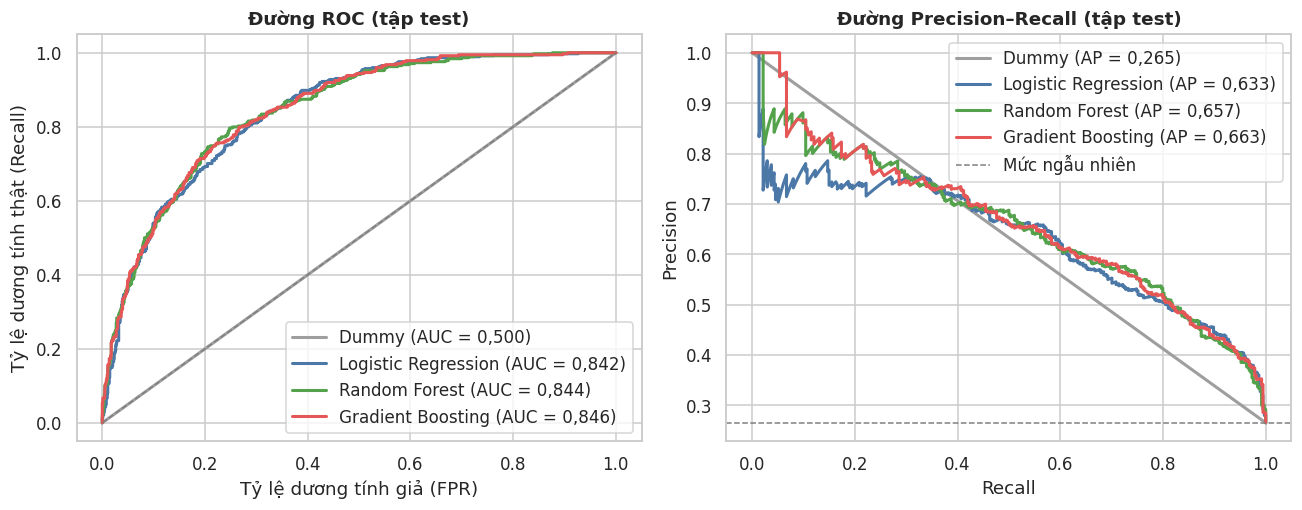

In [6]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for key in MODEL_KEYS:
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, test[key])
    auc_value = roc_auc_score(y_test, test[key])
    axes[0].plot(false_positive_rate, true_positive_rate, color=MODEL_COLORS[key], linewidth=2,
                 label=DISPLAY_NAMES[key] + " (AUC = " + format(auc_value, ".3f").replace(".", ",") + ")")
    precision_values, recall_values, _ = precision_recall_curve(y_test, test[key])
    ap_value = average_precision_score(y_test, test[key])
    axes[1].plot(recall_values, precision_values, color=MODEL_COLORS[key], linewidth=2,
                 label=DISPLAY_NAMES[key] + " (AP = " + format(ap_value, ".3f").replace(".", ",") + ")")
axes[0].plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1)
axes[0].set_title("Đường ROC (tập test)")
axes[0].set_xlabel("Tỷ lệ dương tính giả (FPR)")
axes[0].set_ylabel("Tỷ lệ dương tính thật (Recall)")
axes[0].legend(loc="lower right")
axes[1].axhline(y_test.mean(), color="gray", linestyle="--", linewidth=1, label="Mức ngẫu nhiên")
axes[1].set_title("Đường Precision–Recall (tập test)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="upper right")
save_figure(figure, "model_02_roc_pr_test.png")
plt.show()

Đã lưu hình : /home/claude/proj/ml/results/figures/model_03_top_k_coverage.png


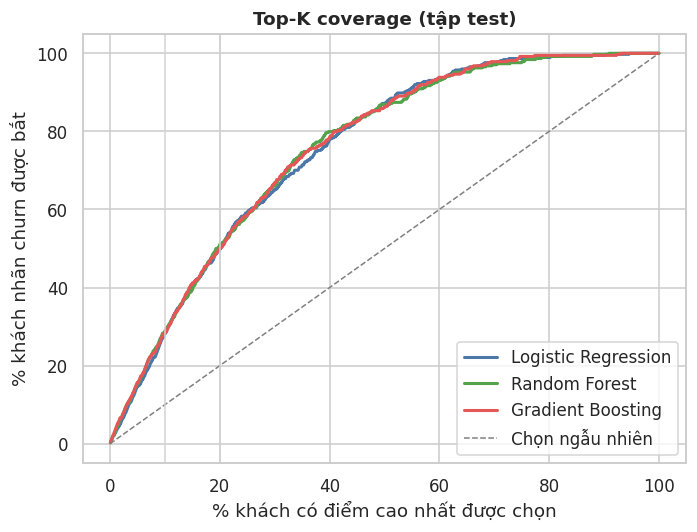

In [7]:
# Biểu đồ lợi ích tích lũy (top-K coverage): chọn K% khách có điểm cao nhất thì bắt được bao nhiêu % khách có nhãn churn
figure, axis = plt.subplots(figsize=(6.5, 5))
number_of_customers = len(y_test)
fractions = np.arange(1, number_of_customers + 1) / number_of_customers
for key in [k for k in MODEL_KEYS if k != "Dummy"]:  # Dummy cho điểm hằng số nên không vẽ
    order = np.argsort(-test[key].to_numpy(), kind="stable")
    cumulative_caught = np.cumsum(y_test[order]) / y_test.sum()
    axis.plot(fractions * 100, cumulative_caught * 100, color=MODEL_COLORS[key], linewidth=2, label=DISPLAY_NAMES[key])
axis.plot([0, 100], [0, 100], color="gray", linestyle="--", linewidth=1, label="Chọn ngẫu nhiên")
for fraction in (0.10, 0.20):
    axis.axvline(fraction * 100, color="lightgray", linewidth=1)
axis.set_title("Top-K coverage (tập test)")
axis.set_xlabel("% khách có điểm cao nhất được chọn")
axis.set_ylabel("% khách nhãn churn được bắt")
axis.legend(loc="lower right")
save_figure(figure, "model_03_top_k_coverage.png")
plt.show()

## 4. Ngưỡng Medium / High và confusion matrix

- **Medium** = ngưỡng cao nhất mà Recall >= 0,75 trên điểm out-of-fold (cảnh báo sớm, ưu tiên không bỏ sót).
- **High** = ngưỡng thấp nhất mà Precision >= 0,60 trên điểm out-of-fold (nhóm nên xem trước), có kèm số khách gắn cờ tối thiểu để tránh chọn ngưỡng ở đuôi chỉ có vài khách.

Hai giá trị này là **giá trị khởi tạo** cho `RiskConfig`; sửa được từ web (R-04).

In [8]:
threshold_table

,Mức,Quy tắc chọn,Ngưỡng,Precision (out-of-fold),Recall (out-of-fold),Precision (test),Recall (test),F1 (test),Tỷ lệ khách bị gắn cờ (test)
0,Medium,Recall >= 0.75 trên điểm out-of-fold,0.3148,0.5554,0.7505,0.5401,0.7567,0.6303,0.3719
1,High,"Precision >= 0.60 trên điểm out-of-fold, gắn c...",0.3866,0.6001,0.6635,0.5853,0.6791,0.6287,0.3080


Đã lưu hình : /home/claude/proj/ml/results/figures/model_04_chon_nguong.png


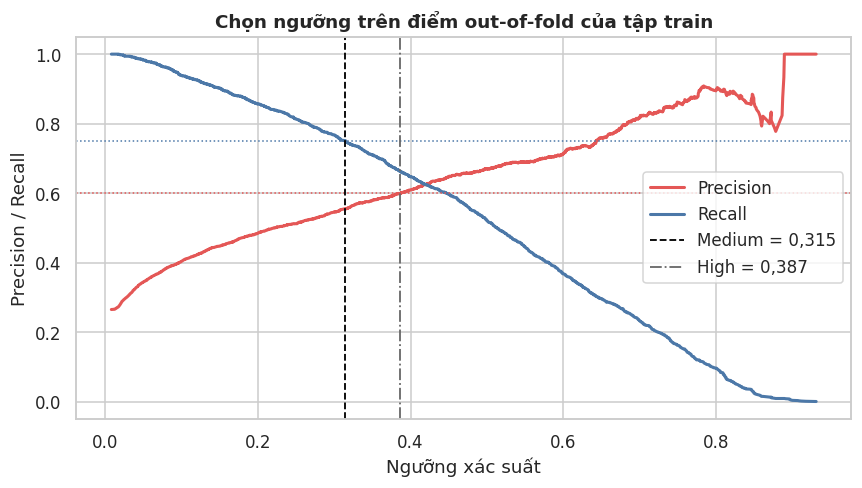

In [9]:
figure, axis = plt.subplots(figsize=(8, 4.6))
precision_values, recall_values, thresholds_values = precision_recall_curve(y_train, oof["selected"])
axis.plot(thresholds_values, precision_values[:-1], color=COLOR_CHURN, linewidth=2, label="Precision")
axis.plot(thresholds_values, recall_values[:-1], color=COLOR_STAY, linewidth=2, label="Recall")
axis.axhline(0.75, color=COLOR_STAY, linestyle=":", linewidth=1)
axis.axhline(0.60, color=COLOR_CHURN, linestyle=":", linewidth=1)
axis.axvline(meta["threshold_medium"], color="black", linestyle="--", linewidth=1.2,
             label="Medium = " + format(meta["threshold_medium"], ".3f").replace(".", ","))
if meta["threshold_high"] is not None:
    axis.axvline(meta["threshold_high"], color="dimgray", linestyle="-.", linewidth=1.2,
                 label="High = " + format(meta["threshold_high"], ".3f").replace(".", ","))
axis.set_title("Chọn ngưỡng trên điểm out-of-fold của tập train")
axis.set_xlabel("Ngưỡng xác suất")
axis.set_ylabel("Precision / Recall")
axis.legend(loc="center right")
save_figure(figure, "model_04_chon_nguong.png")
plt.show()

Đã lưu hình : /home/claude/proj/ml/results/figures/model_05_confusion_matrix.png


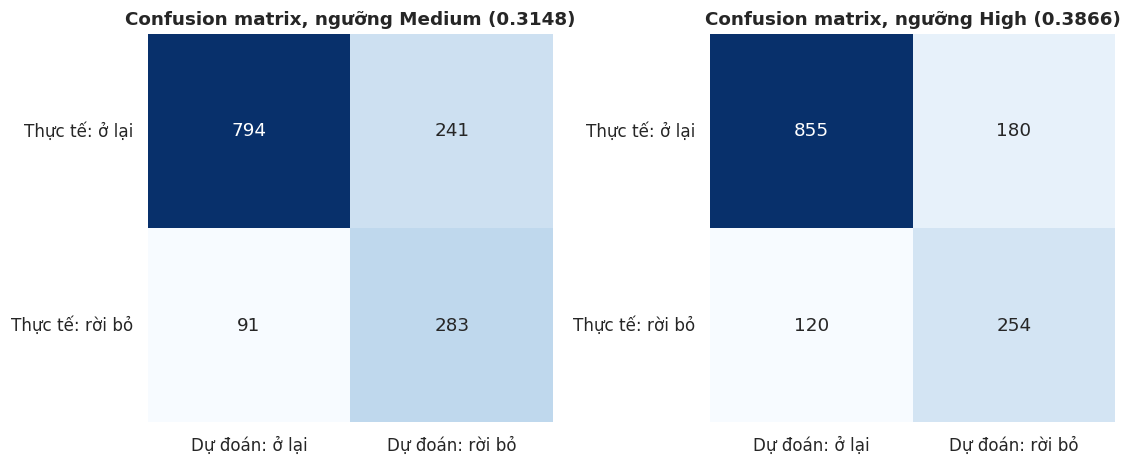

In [10]:
levels = list(confusion_table["Ngưỡng"])
figure, axes = plt.subplots(1, len(levels), figsize=(5.2 * len(levels), 4.4))
if len(levels) == 1:
    axes = [axes]
for axis, (_, row) in zip(axes, confusion_table.iterrows()):
    matrix = np.array([[row["TN"], row["FP"]], [row["FN"], row["TP"]]])
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axis,
                xticklabels=["Dự đoán: ở lại", "Dự đoán: rời bỏ"], yticklabels=["Thực tế: ở lại", "Thực tế: rời bỏ"])
    axis.set_title("Confusion matrix, ngưỡng " + row["Ngưỡng"])
    axis.tick_params(axis="y", rotation=0)
save_figure(figure, "model_05_confusion_matrix.png")
plt.show()

## 5. Calibration và độ tin cậy của xác suất

Nếu giao diện hiển thị "xác suất churn = 0,xx" thì xác suất phải đáng tin: trong số khách được chấm khoảng 0,3 thì thực tế khoảng 30% có nhãn churn. Đường calibration càng gần đường chéo càng tốt; Brier càng thấp càng tốt.

Đã lưu hình : /home/claude/proj/ml/results/figures/model_06_calibration.png


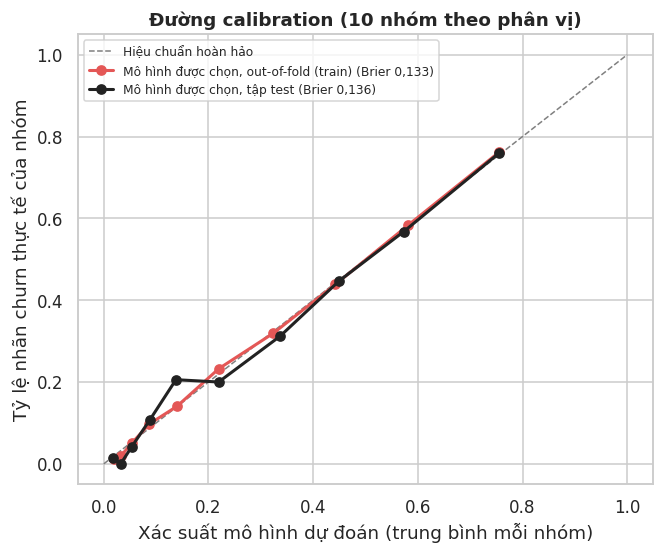

Brier out-of-fold: bản gốc = 0.1335 | bản hiệu chuẩn = 0.1333 | dùng bản hiệu chuẩn: False


In [11]:
figure, axis = plt.subplots(figsize=(6.2, 5.2))
axis.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1, label="Hiệu chuẩn hoàn hảo")

series_to_plot = [("selected", "Mô hình được chọn", COLOR_CHURN, oof, y_train, "out-of-fold (train)"),
                  ("selected", "Mô hình được chọn", "#222222", test, y_test, "tập test")]
for column, label, color, frame, y_values, source_text in series_to_plot:
    observed, predicted = calibration_curve(y_values, frame[column], n_bins=10, strategy="quantile")
    brier = brier_score_loss(y_values, frame[column])
    axis.plot(predicted, observed, marker="o", color=color, linewidth=2,
              label=label + ", " + source_text + " (Brier " + format(brier, ".3f").replace(".", ",") + ")")
if meta["calibrated"]:
    base_key = meta["model_key"]
    observed, predicted = calibration_curve(y_test, test[base_key], n_bins=10, strategy="quantile")
    brier = brier_score_loss(y_test, test[base_key])
    axis.plot(predicted, observed, marker="s", color="#999999", linewidth=1.5, linestyle=":",
              label="Bản gốc chưa hiệu chuẩn, tập test (Brier " + format(brier, ".3f").replace(".", ",") + ")")
axis.set_title("Đường calibration (10 nhóm theo phân vị)")
axis.set_xlabel("Xác suất mô hình dự đoán (trung bình mỗi nhóm)")
axis.set_ylabel("Tỷ lệ nhãn churn thực tế của nhóm")
axis.legend(loc="upper left", fontsize=8)
save_figure(figure, "model_06_calibration.png")
plt.show()

print("Brier out-of-fold: bản gốc =", round(meta["metrics_cv"]["brier_out_of_fold_base"], 4),
      "| bản hiệu chuẩn =", round(meta["metrics_cv"]["brier_out_of_fold_calibrated"], 4),
      "| dùng bản hiệu chuẩn:", meta["calibrated"])

## 6. Phân tích lỗi: False Negative và False Positive

Tại ngưỡng **Medium** trên tập test:
- **False Negative (FN):** khách có nhãn churn nhưng mô hình không gắn cờ (bị bỏ sót).
- **False Positive (FP):** khách bị gắn cờ nhưng nhãn là ở lại.

In [12]:
medium_threshold = meta["threshold_medium"]
analysis = test_features.copy()
analysis["customerID"] = test["customerID"].to_numpy()
analysis["y_true"] = y_test
analysis["score"] = test["selected"].to_numpy()
analysis["predicted"] = (analysis["score"] >= medium_threshold).astype(int)
analysis["Loại"] = np.select(
    [(analysis["y_true"] == 1) & (analysis["predicted"] == 1),
     (analysis["y_true"] == 0) & (analysis["predicted"] == 1),
     (analysis["y_true"] == 1) & (analysis["predicted"] == 0)],
    ["TP (bắt đúng)", "FP (gắn cờ nhầm)", "FN (bỏ sót)"], default="TN (đúng, ở lại)")

profile_rows = []
for group_name in ["TP (bắt đúng)", "FP (gắn cờ nhầm)", "FN (bỏ sót)", "TN (đúng, ở lại)"]:
    part = analysis[analysis["Loại"] == group_name]
    profile_rows.append({
        "Loại": group_name,
        "Số khách": len(part),
        "Điểm TB": round(part["score"].mean(), 3),
        "tenure TB (tháng)": round(part["tenure"].mean(), 1),
        "Mức phí hằng tháng TB (dữ liệu mẫu)": round(part["MonthlyCharges"].mean(), 1),
        "% hợp đồng Month-to-month": round((part["Contract"] == "Month-to-month").mean() * 100, 1),
        "% Internet Fiber optic": round((part["InternetService"] == "Fiber optic").mean() * 100, 1),
        "% thanh toán Electronic check": round((part["PaymentMethod"] == "Electronic check").mean() * 100, 1),
    })
profile_table = pd.DataFrame(profile_rows)
save_table(profile_table, "model_06_ho_so_loi.csv")
profile_table

Đã lưu bảng : /home/claude/proj/ml/results/metrics/model_06_ho_so_loi.csv


,Loại,Số khách,Điểm TB,tenure TB (tháng),Mức phí hằng tháng TB (dữ liệu mẫu),% hợp đồng Month-to-month,% Internet Fiber optic,% thanh toán Electronic check
0,TP (bắt đúng),283,0.593,11.8,75.0,99.3,77.0,63.6
1,FP (gắn cờ nhầm),241,0.491,17.8,74.6,97.9,71.8,57.7
2,FN (bỏ sót),91,0.168,30.9,65.9,52.7,37.4,28.6
3,"TN (đúng, ở lại)",794,0.093,43.5,56.8,26.2,23.7,16.2


In [13]:
show_columns = ["customerID", "score", "tenure", "MonthlyCharges", "Contract", "InternetService", "PaymentMethod"]
false_negative_sample = (analysis[analysis["Loại"] == "FN (bỏ sót)"].sort_values("score").head(15)[show_columns]
                         .rename(columns={"score": "Điểm mô hình"}).round({"Điểm mô hình": 3}))
false_positive_sample = (analysis[analysis["Loại"] == "FP (gắn cờ nhầm)"].sort_values("score", ascending=False).head(15)[show_columns]
                         .rename(columns={"score": "Điểm mô hình"}).round({"Điểm mô hình": 3}))
save_table(false_negative_sample, "model_07_mau_false_negative.csv")
save_table(false_positive_sample, "model_08_mau_false_positive.csv")
print("15 khách FN có điểm THẤP nhất (mô hình tin chắc là ở lại nhưng nhãn là churn):")
display(false_negative_sample)
print("15 khách FP có điểm CAO nhất (mô hình tin chắc là rời bỏ nhưng nhãn là ở lại):")
display(false_positive_sample)

Đã lưu bảng : /home/claude/proj/ml/results/metrics/model_07_mau_false_negative.csv
Đã lưu bảng : /home/claude/proj/ml/results/metrics/model_08_mau_false_positive.csv
15 khách FN có điểm THẤP nhất (mô hình tin chắc là ở lại nhưng nhãn là churn):


,customerID,Điểm mô hình,tenure,MonthlyCharges,Contract,InternetService,PaymentMethod
1099,3400-ESFUW,0.020,55,57.55,Two year,DSL,Bank transfer (automatic)
687,8580-QVLOC,0.020,72,92.45,Two year,DSL,Credit card (automatic)
931,8869-TORSS,0.047,48,60.35,One year,DSL,Credit card (automatic)
61,3705-PSNGL,0.054,45,20.40,One year,No,Electronic check
951,0866-QLSIR,0.054,34,64.40,One year,DSL,Mailed check
297,1218-VKFPE,0.055,12,19.00,Month-to-month,No,Mailed check
1145,9412-ARGBX,0.055,48,95.50,Two year,Fiber optic,Mailed check
849,0628-CNQRM,0.062,22,67.50,One year,DSL,Bank transfer (automatic)
796,2325-ZUSFD,0.069,57,70.10,One year,DSL,Bank transfer (automatic)
418,6598-RFFVI,0.072,2,19.30,One year,No,Credit card (automatic)


15 khách FP có điểm CAO nhất (mô hình tin chắc là rời bỏ nhưng nhãn là ở lại):


,customerID,Điểm mô hình,tenure,MonthlyCharges,Contract,InternetService,PaymentMethod
995,8161-QYMTT,0.832,7,94.10,Month-to-month,Fiber optic,Electronic check
733,2254-DLXRI,0.815,1,79.15,Month-to-month,Fiber optic,Mailed check
952,1628-BIZYP,0.814,1,85.00,Month-to-month,Fiber optic,Electronic check
1222,8775-ERLNB,0.813,1,74.30,Month-to-month,Fiber optic,Electronic check
41,4927-WWOOZ,0.813,2,91.45,Month-to-month,Fiber optic,Electronic check
629,5542-TBBWB,0.802,1,69.90,Month-to-month,Fiber optic,Electronic check
889,2545-EBUPK,0.797,2,84.05,Month-to-month,Fiber optic,Electronic check
1355,6630-UJZMY,0.795,4,83.25,Month-to-month,Fiber optic,Electronic check
454,6969-MVBAI,0.788,9,90.10,Month-to-month,Fiber optic,Electronic check
814,8739-XNIKG,0.785,5,84.00,Month-to-month,Fiber optic,Electronic check


## 7. Metric theo nhóm nghiệp vụ

Xem mô hình yếu ở nhóm nào: loại hợp đồng, nhóm tenure (D-05), dịch vụ Internet, phương thức thanh toán. Ngưỡng Medium, tập test. **Chỉ để phát hiện chỗ mô hình kém**, không dùng để đối xử khác biệt với khách hàng (R-07). Nhóm có **ít khách nhãn churn** (ví dụ Two year chỉ khoảng 9 khách trong test) thì Recall/Precision rất kém ổn định dù nhóm có nhiều khách; vì vậy bảng có cột "Số khách nhãn churn".

In [14]:
tenure_bins = [-1, 6, 12, 24, 36, 48, 60, 1000]
tenure_labels = ["0–6", "7–12", "13–24", "25–36", "37–48", "49–60", ">60"]
group_frame = test_features.copy()
group_frame["Nhóm tenure"] = pd.cut(group_frame["tenure"], bins=tenure_bins, labels=tenure_labels).astype(str)

group_definitions = [
    ("Contract", "Loại hợp đồng", ["Month-to-month", "One year", "Two year"]),
    ("Nhóm tenure", "Nhóm tenure (tháng)", tenure_labels),
    ("InternetService", "Dịch vụ Internet", ["DSL", "Fiber optic", "No"]),
    ("PaymentMethod", "Phương thức thanh toán",
     ["Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"]),
]
group_tables = []
for column_name, label, order in group_definitions:
    group_tables.append(evaluate.metrics_by_group(
        group_frame, y_test, test["selected"], medium_threshold, column_name, label, order))
group_metric_table = pd.concat(group_tables, ignore_index=True)
save_table(group_metric_table, "model_09_metric_theo_nhom.csv")
group_metric_table

Đã lưu bảng : /home/claude/proj/ml/results/metrics/model_09_metric_theo_nhom.csv


,Chỉ tiêu nhóm,Nhóm,Số khách,Số khách nhãn churn,Tỷ lệ nhãn churn (%),Tỷ lệ bị gắn cờ (%),Precision,Recall,FP,FN
0,Loại hợp đồng,Month-to-month,773,329,42.56,66.88,0.544,0.854,236,48
1,Loại hợp đồng,One year,300,36,12.00,2.33,0.286,0.056,5,34
2,Loại hợp đồng,Two year,336,9,2.68,0.00,NaN,0.000,0,9
3,Nhóm tenure (tháng),0–6,311,173,55.63,78.14,0.638,0.896,88,18
4,Nhóm tenure (tháng),7–12,138,42,30.43,47.83,0.439,0.690,37,13
5,Nhóm tenure (tháng),13–24,206,60,29.13,48.06,0.495,0.817,50,11
6,Nhóm tenure (tháng),25–36,163,40,24.54,34.36,0.518,0.725,27,11
7,Nhóm tenure (tháng),37–48,141,24,17.02,21.28,0.333,0.417,20,14
8,Nhóm tenure (tháng),49–60,174,19,10.92,12.64,0.364,0.421,14,11
9,Nhóm tenure (tháng),>60,276,16,5.80,2.90,0.375,0.188,5,13


Đã lưu hình : /home/claude/proj/ml/results/figures/model_07_metric_theo_nhom.png


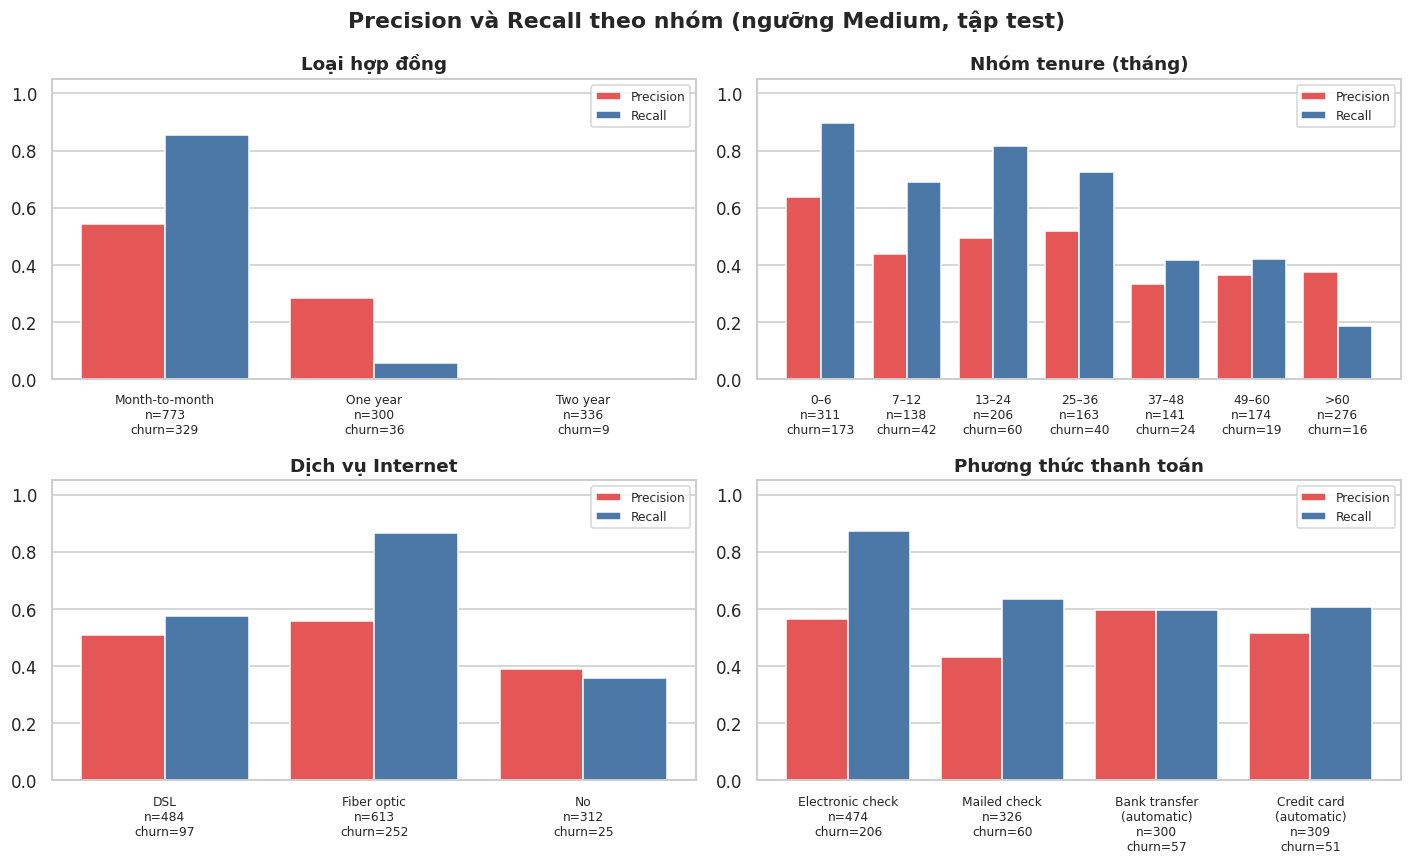

In [15]:
figure, axes = plt.subplots(2, 2, figsize=(13, 8))
for axis, (column_name, label, order) in zip(axes.ravel(), group_definitions):
    part = group_metric_table[group_metric_table["Chỉ tiêu nhóm"] == label]
    positions = np.arange(len(part))
    axis.bar(positions - 0.2, part["Precision"].fillna(0), width=0.4, color=COLOR_CHURN, label="Precision")
    axis.bar(positions + 0.2, part["Recall"].fillna(0), width=0.4, color=COLOR_STAY, label="Recall")
    axis.set_xticks(positions)
    axis.set_xticklabels([str(v).replace(" (automatic)", "\n(automatic)") + "\nn=" + format_count(n) + "\nchurn=" + format_count(c)
                          for v, n, c in zip(part["Nhóm"], part["Số khách"], part["Số khách nhãn churn"])], fontsize=8)
    axis.grid(axis="x", visible=False)
    axis.set_ylim(0, 1.05)
    axis.set_title(label)
    axis.legend(loc="upper right", fontsize=8)
figure.suptitle("Precision và Recall theo nhóm (ngưỡng Medium, tập test)", fontweight="bold")
save_figure(figure, "model_07_metric_theo_nhom.png")
plt.show()

## 8. Các điểm đáng chú ý (tính tự động từ kết quả)

In [16]:
selected_row = test_table[test_table["Được chọn"] == "Có"].iloc[0]
logreg_row = test_table[test_table["Mô hình"] == "Logistic Regression"].iloc[0]
medium_metrics = threshold_table[threshold_table["Mức"] == "Medium"].iloc[0]

print("- Mô hình được chọn:", meta["model_name"], "| tham số:", json.dumps(meta["best_params"], ensure_ascii=False))
print("- Trên test: PR-AUC", selected_row["PR-AUC"], "| ROC-AUC", selected_row["ROC-AUC"], "| Brier", selected_row["Brier"],
      "| so với Logistic Regression: PR-AUC", logreg_row["PR-AUC"], ", ROC-AUC", logreg_row["ROC-AUC"], ", Brier", logreg_row["Brier"])
print("- Ngưỡng Medium", medium_metrics["Ngưỡng"], ": Precision", medium_metrics["Precision (test)"],
      ", Recall", medium_metrics["Recall (test)"], ", gắn cờ", format_percent(medium_metrics["Tỷ lệ khách bị gắn cờ (test)"] * 100), "số khách.")
print("- Top 10% khách điểm cao nhất bắt được", format_percent(selected_row["Top 10% coverage"] * 100),
      "số khách churn; top 20% bắt được", format_percent(selected_row["Top 20% coverage"] * 100), "(chọn ngẫu nhiên: khoảng 10% và 20%).")

# Chỉ xét nhóm có đủ khách nhãn churn (>= 30) để Recall có ý nghĩa
valid_groups = group_metric_table[group_metric_table["Số khách nhãn churn"] >= 30].dropna(subset=["Recall"]).sort_values("Recall")
for _, group_row in valid_groups.head(3).iterrows():
    print("- Recall thấp:", group_row["Chỉ tiêu nhóm"], "=", group_row["Nhóm"], "(Recall", group_row["Recall"],
          ", Precision", group_row["Precision"], ", n=" + format_count(group_row["Số khách"]),
          ", khách nhãn churn=" + format_count(group_row["Số khách nhãn churn"]) + ")")
best_group = valid_groups.iloc[-1]
print("- Recall cao nhất:", best_group["Chỉ tiêu nhóm"], "=", best_group["Nhóm"], "(Recall", best_group["Recall"],
      ", n=" + format_count(best_group["Số khách"]) + ")")
flagged_customers = analysis[analysis["predicted"] == 1]
print("- Trong số khách bị gắn cờ ở ngưỡng Medium,", format_percent((flagged_customers["Contract"] == "Month-to-month").mean() * 100),
      "là hợp đồng Month-to-month (toàn bộ khách test có", format_percent((analysis["Contract"] == "Month-to-month").mean() * 100) + ").",
      "Nghĩa là mô hình chủ yếu gắn cờ nhóm hợp đồng theo tháng.")
print("- Số FN (bỏ sót):", int((analysis["Loại"] == "FN (bỏ sót)").sum()), "| số FP (gắn cờ nhầm):", int((analysis["Loại"] == "FP (gắn cờ nhầm)").sum()))

- Mô hình được chọn: Gradient Boosting | tham số: {"learning_rate": 0.05, "max_depth": 2, "n_estimators": 200}
- Trên test: PR-AUC 0.663 | ROC-AUC 0.8457 | Brier 0.1356 | so với Logistic Regression: PR-AUC 0.6334 , ROC-AUC 0.8419 , Brier 0.1381
- Ngưỡng Medium 0.3148 : Precision 0.5401 , Recall 0.7567 , gắn cờ 37,2% số khách.
- Top 10% khách điểm cao nhất bắt được 28,6% số khách churn; top 20% bắt được 50,0% (chọn ngẫu nhiên: khoảng 10% và 20%).
- Recall thấp: Loại hợp đồng = One year (Recall 0.056 , Precision 0.286 , n=300 , khách nhãn churn=36)
- Recall thấp: Dịch vụ Internet = DSL (Recall 0.577 , Precision 0.509 , n=484 , khách nhãn churn=97)
- Recall thấp: Phương thức thanh toán = Bank transfer (automatic) (Recall 0.596 , Precision 0.596 , n=300 , khách nhãn churn=57)
- Recall cao nhất: Nhóm tenure (tháng) = 0–6 (Recall 0.896 , n=311)
- Trong số khách bị gắn cờ ở ngưỡng Medium, 98,7% là hợp đồng Month-to-month (toàn bộ khách test có 54,9%). Nghĩa là mô hình chủ yếu gắn cờ nhóm hợp 

## 9. Giới hạn khi đọc kết quả (đưa vào báo cáo mục 4.9 và Chương 5)

1. **Dữ liệu mẫu (R-12).** IBM Telco là bộ dữ liệu minh họa. Kết quả không thể suy rộng sang doanh nghiệp thực tế hay sang Việt Nam.
2. **Chênh lệch giữa mô hình nhỏ.** Nếu PR-AUC của hai mô hình chênh nhau ít hơn độ lệch chuẩn giữa các fold (mục 2) thì **chưa đủ cơ sở** nói mô hình nào hơn đáng kể. Notebook chưa tính khoảng tin cậy.
3. **Chọn tham số và đánh giá dùng chung các fold.** Tham số được chọn bằng PR-AUC trên chính 5 fold dùng để báo cáo điểm CV, nên điểm CV có thể hơi lạc quan. Tập test (chưa dùng để chọn gì) là thước đo công bằng hơn.
4. **Ngưỡng chọn từ CV, áp lên test.** Recall thực tế trên test có thể lệch nhẹ so với mục tiêu 0,75 vì test chỉ có khoảng 1.400 khách; đó là biến thiên ngẫu nhiên, không phải lỗi.
5. **Điểm không phải nhân quả (R-02).** Mô hình chỉ cho biết khách nào *có điểm cao theo dữ liệu mẫu*, không cho biết *vì sao* họ rời bỏ. Giải thích SHAP và ontology thuộc Mức 2.
6. **Hỗ trợ quyết định, không tự động hóa (R-07).** Điểm và mức Low/Medium/High chỉ để nhân viên chăm sóc cân nhắc ưu tiên.
7. **Số liệu theo nhóm (mục 7)** chỉ để tìm chỗ mô hình yếu. Phân tích công bằng sâu theo gender và SeniorCitizen thuộc Mức 2.

In [17]:
print("HÌNH (ml/results/figures):")
for path in sorted(FIGURE_FOLDER.glob("model_*.png")):
    print("  -", path.name)
print("BẢNG (ml/results/metrics):")
for path in sorted(METRICS_FOLDER.glob("model_*.csv")):
    print("  -", path.name)

HÌNH (ml/results/figures):
  - model_01_pr_auc_cv.png
  - model_02_roc_pr_test.png
  - model_03_top_k_coverage.png
  - model_04_chon_nguong.png
  - model_05_confusion_matrix.png
  - model_06_calibration.png
  - model_07_metric_theo_nhom.png
BẢNG (ml/results/metrics):
  - model_00_tom_tat_protocol.csv
  - model_01_luoi_tham_so_cv.csv
  - model_02_so_sanh_cv.csv
  - model_03_so_sanh_test.csv
  - model_04_nguong.csv
  - model_05_confusion_matrix.csv
  - model_06_ho_so_loi.csv
  - model_07_mau_false_negative.csv
  - model_08_mau_false_positive.csv
  - model_09_metric_theo_nhom.csv
